# Data Analysis of the Indian Pines HSI dataset

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Reading dataset 

In [2]:
pixels_df = pd.read_csv("../dataset/pixels.csv")


### Analysis :

In [3]:
pixels_df.head()

,band-1,band-2,band-3,band-4,band-5,band-6,band-7,band-8,band-9,band-10,...,band-192,band-193,band-194,band-195,band-196,band-197,band-198,band-199,band-200,class
0,3172,4142,4506,4279,4782,5048,5213,5106,5053,4750,...,1094,1090,1112,1090,1062,1069,1057,1020,1020,3
1,2580,4266,4502,4426,4853,5249,5352,5353,5347,5065,...,1108,1104,1117,1091,1079,1085,1064,1029,1020,3
2,3687,4266,4421,4498,5019,5293,5438,5427,5383,5132,...,1111,1114,1114,1100,1065,1092,1061,1030,1016,3
3,2749,4258,4603,4493,4958,5234,5417,5355,5349,5096,...,1122,1108,1109,1109,1071,1088,1060,1030,1006,3
4,2746,4018,4675,4417,4886,5117,5215,5096,5098,4834,...,1110,1107,1112,1094,1072,1087,1052,1034,1019,3


In [4]:
print( "Shape of the data",pixels_df.shape)

Shape of the data (21025, 201)


We have 21025 pixels with their corresponding 200 band's values and class value

In [5]:
# number of unique classes
print(pixels_df["class"].unique())

[ 3  0 15 11 12  5 10 14 16  2  4  8  6  9  1  7 13]


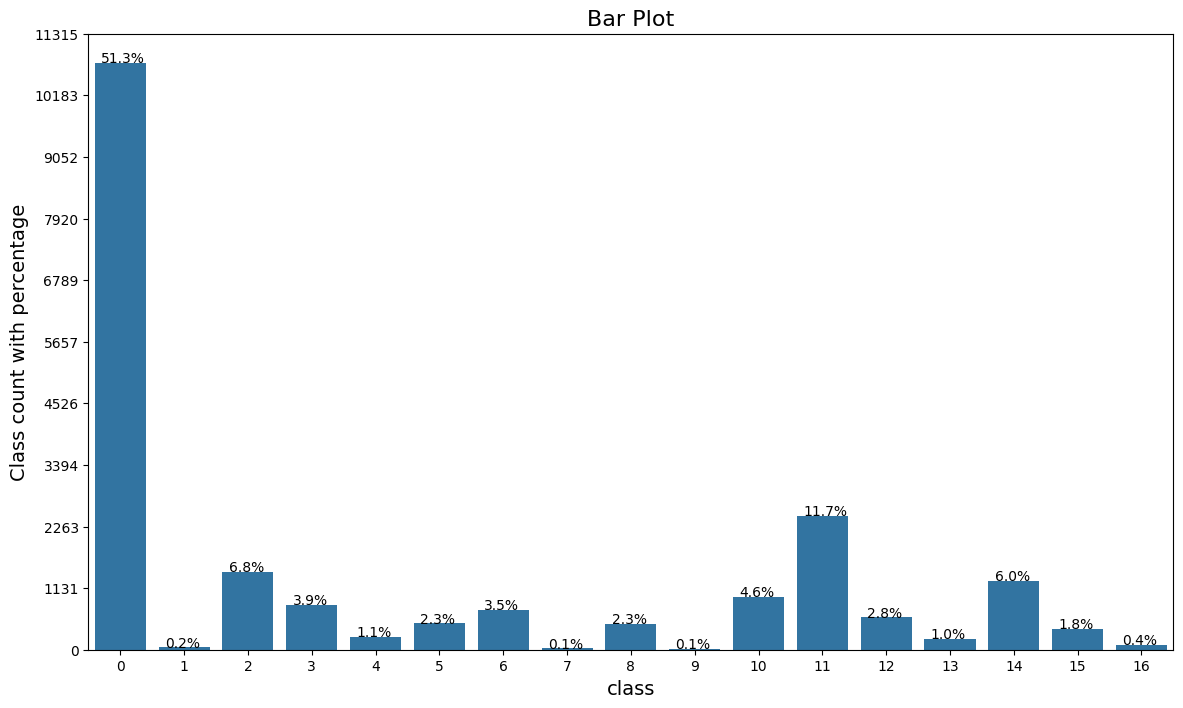

In [6]:
from matplotlib import ticker


plt.figure(figsize=(14, 8))

ax = sns.countplot(x='class', data=pixels_df[['class']])

for p in ax.patches:
        ax.annotate('{:.1f}%'.format(100*p.get_height()/pixels_df.shape[0]), (p.get_x()+0.1, p.get_height()+5))
        ax.yaxis.set_major_locator(ticker.LinearLocator(11))

plt.ylabel('Class count with percentage', fontsize=14)
plt.xlabel('class', fontsize=14)
plt.title('Bar Plot', fontsize=16)
plt.show()

- This graph shows the distribution of the different classes by their presence in the image and as we can see 50% of pixels are of class 0 so we need to take into consideration the distribution of classes when we split our dataset into training and testing datasets

### Visualizing a Pixel

Usually the pixel of the indian pines HSI is a one dimensional vector with size (1, 200) ad the HSI has 200 bands.


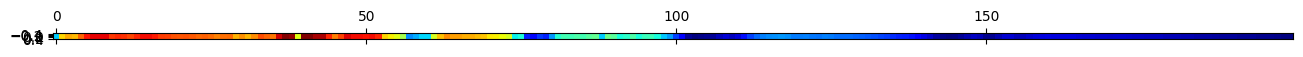

In [14]:
# Visualizing the pixel
plt.matshow(pixels_df.iloc[1, :-1].values.reshape(1,200), cmap='jet')

It is difficult to interpret the visualization of a vetor. So, to overcome this problem the pixel vector is reshape into a 2-Dimensional array.
* 200 => 10 X 20
* (1, 200) => (10, 20)

In [15]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
def plot_pixel(pixel, n):
    ax = plt.gca()
    im = ax.imshow(pixel.reshape(10, 20), cmap = 'jet')
    plt.title(f'pixel - {n}')
    plt.axis('off')
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    plt.colorbar(im, cax=cax)
    plt.show()

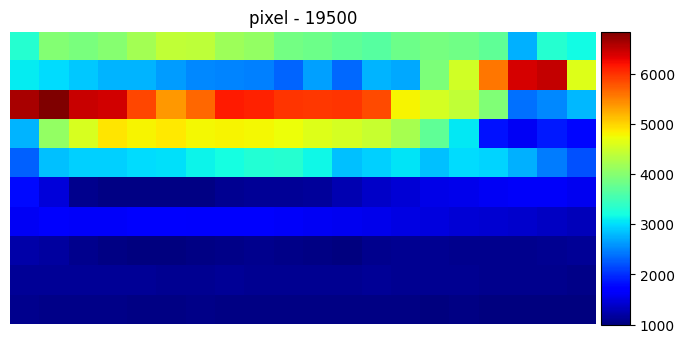

In [29]:
plt.figure(figsize=(8, 4))

rand_n = np.random.randint(pixels_df.shape[0])


plot_pixel(pixels_df.iloc[rand_n, :-1].values, rand_n)

In [22]:
# Details of a specific band n : band number
n = 150
print(f"Details of Band - {n}: \n\n{pixels_df['band-'+str(n)].describe()}")

Details of Band - 150: 

count    21025.000000
mean      1155.830107
std        101.141010
min       1008.000000
25%       1056.000000
50%       1138.000000
75%       1257.000000
max       1545.000000
Name: band-150, dtype: float64


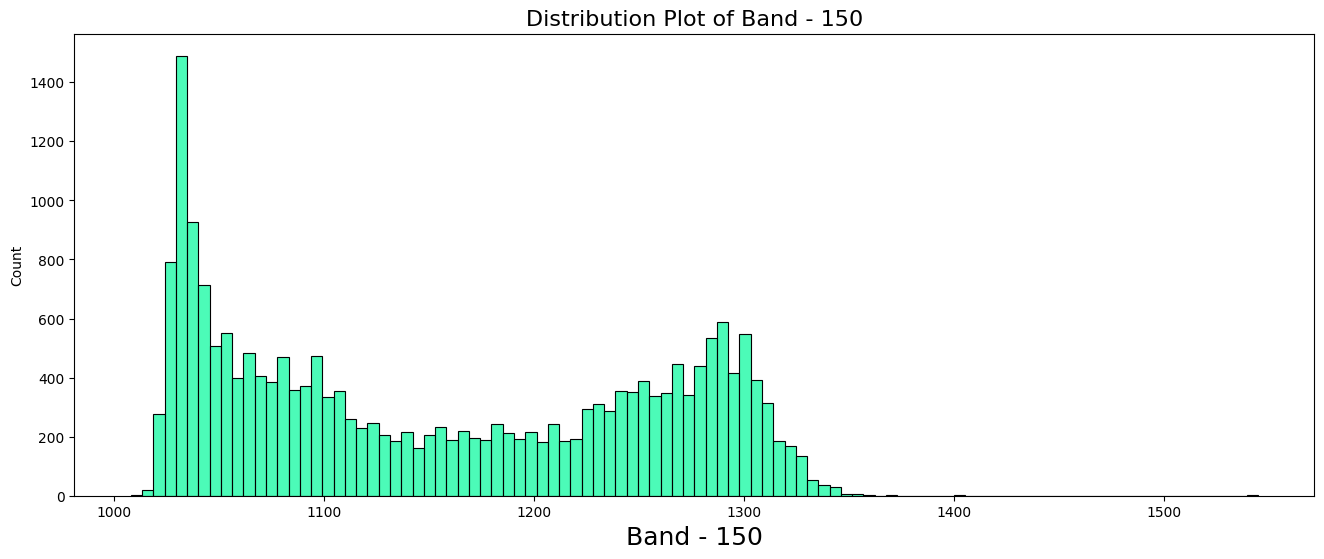

In [27]:
plt.figure(figsize=(16, 6))
sns.histplot(pixels_df['band-'+str(n)], color='mediumSpringGreen', bins=100, alpha=0.7)
plt.xlabel('Band - '+str(n), fontsize=18)
plt.title('Distribution Plot of Band - '+str(n), fontsize=16)
plt.show()